In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import statistics
import matplotlib.ticker as mticker
from tqdm import tqdm


#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
%cd /Users/michelefilippucci/Data/ERA5/
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/Users/michelefilippucci/Data/ERA5
ERA5_2.5x2.5_zg500_daily_1940-2024.nc
ERA5_2m_temperature_day_r144x73_sfc_1979-2019.nc
ERA5_2mt_pr_land_12hrs_northem_2.5x2.5_1940-2023.nc
ERA5_2mt_pr_land_daily_2.5x2.5_jja_1940-2023.nc
ERA5_2mt_pr_land_daily_2.5x2.5_jja_1940-2023_deseasonalized.nc
ERA5_2mt_pr_land_daily_northem_2.5x2.5_1940-2023.nc
ERA5_clim_snowc_0.1x0.1_1980-2000.nc
ERA5_geopotential_day_2.5x2.5_500hPa_1950-2021.nc
ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg500_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_jja_1940-2023_detrended.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_jja_1940-2023_

In [3]:
#IMPORT DATASET
ds = xr.load_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_jja_1940-2023.nc')
ds_comp = xr.load_dataset('ERA5_2mt_pr_land_daily_2.5x2.5_jja_1940-2023_deseasonalized.nc')
#store variables for the composite
DAV = ds['DAV_tracked']
zg = ds['zg']/9.8
anom = ds_comp['t2m'] #2m temperature
lat = ds['lat']
lon = ds['lon']
times = ds['time']

In [4]:
anom.shape

(7728, 37, 144)

In [71]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in range(n_iter):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=True)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

#we subtract to the anom field the annual mean in order to have only deviations from the annual mean and remove the seasonal cycle
dates = []
for time in times:
    if str(time.values)[0:4] == '1940':
        dates.append(str(time.values)[5:10])
    else:
        break
usual_year = np.zeros((len(dates),37,144))
for i,date in tqdm(enumerate(dates)):
    for t,time in enumerate(times):
        if str(time.values)[5:10] == date:
            usual_year[i,:,:] += anom[t,:,:]
usual_year = usual_year/len(dates)
usual_year_repeat = np.repeat(usual_year, 84, axis = 0)
anom = anom - usual_year_repeat

In [94]:
#compute the composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = DAV.loc[:,plat,plon]
list = []
list_an = []
list_east = [63, 232, 283, 288, 380, 460, 508, 519, 574, 756, 820, 931, 935, 988, 1051, 1053, 1113, 1177, 1186, 1414, 1460, 1519, 1530, 1757, 1770, 1993, 2000, 2067, 2123, 2187, 2238, 2288, 2296, 2348, 2464, 2466, 2468, 2475, 2593, 2605, 2764, 2771, 2839, 2845, 2949, 2952, 2957, 3004, 3011, 3066, 3130, 3196, 3204, 3209, 3318, 3375, 3440, 3486, 3493, 3593, 3605, 3649, 3658, 3709, 3726, 3777, 3782, 3783, 3838, 3912, 3916, 4018, 4029, 4084, 4278, 4330, 4478, 4492, 4553, 4609, 4653, 4663, 4718, 4767, 4771]
list_west = [235, 449, 578, 584, 631, 646, 696, 759, 762, 925, 987, 995, 1116, 1297, 1415, 1531, 1589, 1592, 1637, 1879, 1930, 1939, 1943, 1999, 2243, 2342, 2349, 2353, 2402, 2533, 2596, 2658, 2714, 2722, 2892, 2904, 2953, 3002, 3074, 3254, 3262, 3423, 3429, 3532, 3595, 3715, 3724, 3776, 3913, 3959, 3961, 4154, 4266, 4274, 4281, 4323, 4433, 4488, 4489, 4493, 4546, 4726, 4777, 4883]
for t,time in enumerate(times):
    if series[t] > 0:#in list_west:
        list.append(zg.loc[time,:,:].values)
        list_an.append(anom.loc[time,:,:].values)
sum_t = sum(list)
sum_an = sum(list_an)
zg_comp = sum_t/len(list)
anom_comp = -np.mean(anom,axis=0) + sum_an/len(list_an)
t_st_anom = abs(anom_comp/Bootstrap(anom,len(list_an),1000)) > 3.261
bool_tmp = abs(anom_comp) > 0.5
t_st_anom = t_st_anom*bool_tmp


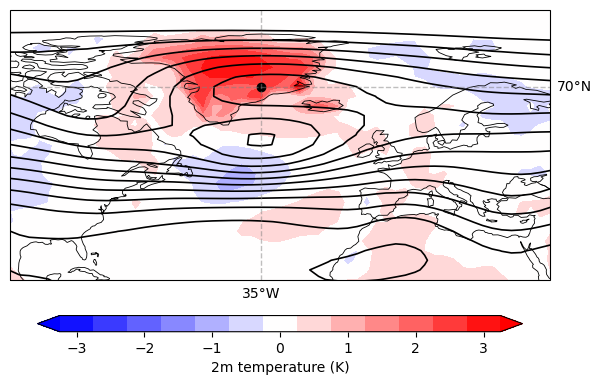

In [97]:
fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(10,4),subplot_kw={'projection': ccrs.PlateCarree()})
title = ''
field = ma.masked_array(zg_comp,zg_comp==0)
extent =[-100,40,20,90] #Greenland
#extent =[-180,180,20,90] #Europe
ax.set_extent(extent, ccrs.PlateCarree())
ax.coastlines(linewidth = 0.6)
ax.plot(plon,plat,color='black', marker='o')
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')
gl.xlocator = mticker.FixedLocator([plon])
gl.ylocator = mticker.FixedLocator([plat])
gl.xlabels_top = False
gl.ylabels_left = False
cont = ax.contour(lon,lat,field,
                    colors = 'black',
                    alpha =1.,
                    linewidths = 1.2,
                    levels = np.arange(4600,7200,40)
                    )
                    #cmap = "YlGnBu")
#c_range = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/8)) + np.array(np.amax(abs(anom_comp))/16)
c_range = np.arange(-3.25,3.35,0.5)
#ticks = np.array(np.arange(-np.amax(abs(anom_comp)),+np.amax(abs(anom_comp)),np.amax(abs(anom_comp))/4)) + np.array(np.amax(abs(anom_comp))/8)
ticks = np.arange(-3.,+3.1,1)
shadings = ax.contourf(lon,lat,anom_comp,
                      cmap='bwr',
                      extend = 'both', 
                      levels = c_range)
#cs_p = ax.contourf(lon,lat,t_st_anom,levels = 1,colors='none',hatches=['','...'])
fig.colorbar(shadings,ticks=ticks,label='2m temperature (K)',pad=0.1,orientation='horizontal',shrink=0.5,aspect=30)
ax.set_title('')
plt.tight_layout()
plt.savefig('/Users/michelefilippucci/PLOTS/EGU/composite_greenland.png',dpi=300)
